In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

- **Number_of_Riders** : nombre de passagers attendus pour la course.
- **Number_of_Drivers** : nombre de conducteurs disponibles ou impliqués dans la course.
- **Location_Category** : catégorie de l/’emplacement de départ ou d/’arrivée (Rural, Suburban, Urban).
- **Customer_Loyalty_Status** : statut de fidélité du client (Gold, Regular, Silver).
- **Number_of_Past_Rides** : nombre de courses déjà effectuées par le client.
- **Average_Ratings** : note moyenne donnée par le client ou reçue par le conducteur.
- **Time_of_Booking** : période de la réservation (Morning, Afternoon, Evening, Night).
- **Vehicle_Type** : type de véhicule utilisé (Economy, Premium).
- **Expected_Ride_Duration** : durée prévue de la course en minutes.
- **Historical_Cost_of_Ride** : coût historique de la course, utilisé pour comparer ou prédire les prix.

In [50]:
path = "../data/raw/dynamic_pricing.csv"

df = pd.read_csv(path, sep=",")
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [51]:
df.columns

Index(['Number_of_Riders', 'Number_of_Drivers', 'Location_Category',
       'Customer_Loyalty_Status', 'Number_of_Past_Rides', 'Average_Ratings',
       'Time_of_Booking', 'Vehicle_Type', 'Expected_Ride_Duration',
       'Historical_Cost_of_Ride'],
      dtype='object')

In [52]:
df.shape

(1000, 10)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Number_of_Drivers        1000 non-null   int64  
 2   Location_Category        1000 non-null   object 
 3   Customer_Loyalty_Status  1000 non-null   object 
 4   Number_of_Past_Rides     1000 non-null   int64  
 5   Average_Ratings          1000 non-null   float64
 6   Time_of_Booking          1000 non-null   object 
 7   Vehicle_Type             1000 non-null   object 
 8   Expected_Ride_Duration   1000 non-null   int64  
 9   Historical_Cost_of_Ride  1000 non-null   float64
dtypes: float64(2), int64(4), object(4)
memory usage: 78.3+ KB


In [54]:
df.isnull().sum()

Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64

In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df.describe()

,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


In [57]:
df.describe(exclude="number")

,Location_Category,Customer_Loyalty_Status,Time_of_Booking,Vehicle_Type
count,1000,1000,1000,1000
unique,3,3,4,2
top,Urban,Silver,Night,Premium
freq,346,367,276,522


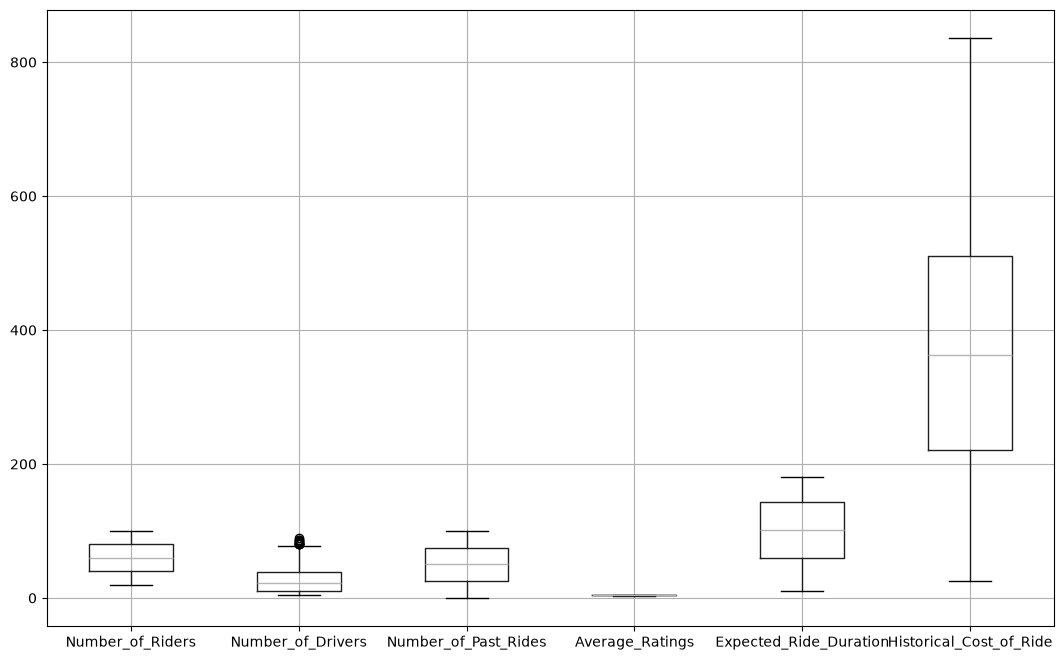

In [58]:
# Outliers
plt.figure(figsize=(13, 8))
df.boxplot()
plt.show()

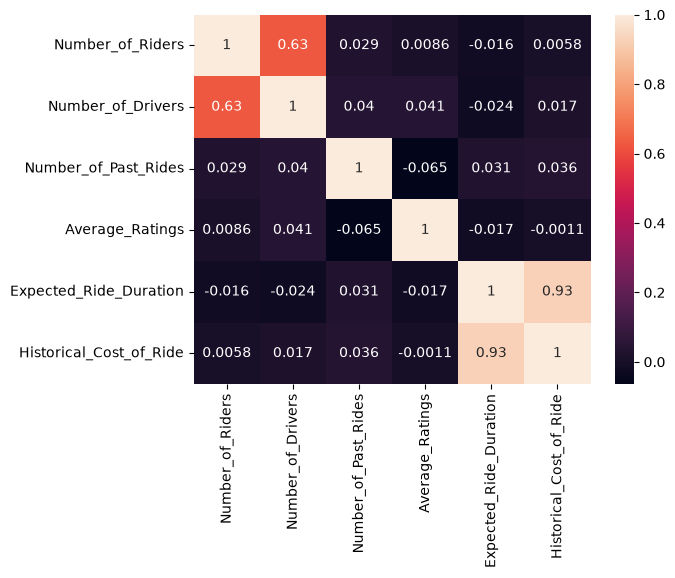

In [59]:
numeric_col = df.select_dtypes("number")
corr = numeric_col.corr()
sns.heatmap(corr, annot=True)
plt.show()

In [60]:
cat_cols = pd.get_dummies(df.select_dtypes('object'), drop_first=False)
cat_cols

,Location_Category_Rural,Location_Category_Suburban,Location_Category_Urban,Customer_Loyalty_Status_Gold,Customer_Loyalty_Status_Regular,Customer_Loyalty_Status_Silver,Time_of_Booking_Afternoon,Time_of_Booking_Evening,Time_of_Booking_Morning,Time_of_Booking_Night,Vehicle_Type_Economy,Vehicle_Type_Premium
0,False,False,True,False,False,True,False,False,False,True,False,True
1,False,True,False,False,False,True,False,True,False,False,True,False
2,True,False,False,False,False,True,True,False,False,False,False,True
3,True,False,False,False,True,False,True,False,False,False,False,True
4,True,False,False,False,True,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
995,False,False,True,True,False,False,False,False,True,False,False,True
996,False,False,True,False,True,False,False,False,True,False,False,True
997,False,True,False,True,False,False,False,False,False,True,False,True
998,False,True,False,False,True,False,False,False,False,True,False,True


In [61]:
df = pd.concat([cat_cols, numeric_col], axis=1)
df.head()

,Location_Category_Rural,Location_Category_Suburban,Location_Category_Urban,Customer_Loyalty_Status_Gold,Customer_Loyalty_Status_Regular,Customer_Loyalty_Status_Silver,Time_of_Booking_Afternoon,Time_of_Booking_Evening,Time_of_Booking_Morning,Time_of_Booking_Night,Vehicle_Type_Economy,Vehicle_Type_Premium,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
0,False,False,True,False,False,True,False,False,False,True,False,True,90,45,13,4.47,90,284.257273
1,False,True,False,False,False,True,False,True,False,False,True,False,58,39,72,4.06,43,173.874753
2,True,False,False,False,False,True,True,False,False,False,False,True,42,31,0,3.99,76,329.795469
3,True,False,False,False,True,False,True,False,False,False,False,True,89,28,67,4.31,134,470.201232
4,True,False,False,False,True,False,True,False,False,False,True,False,78,22,74,3.77,149,579.681422


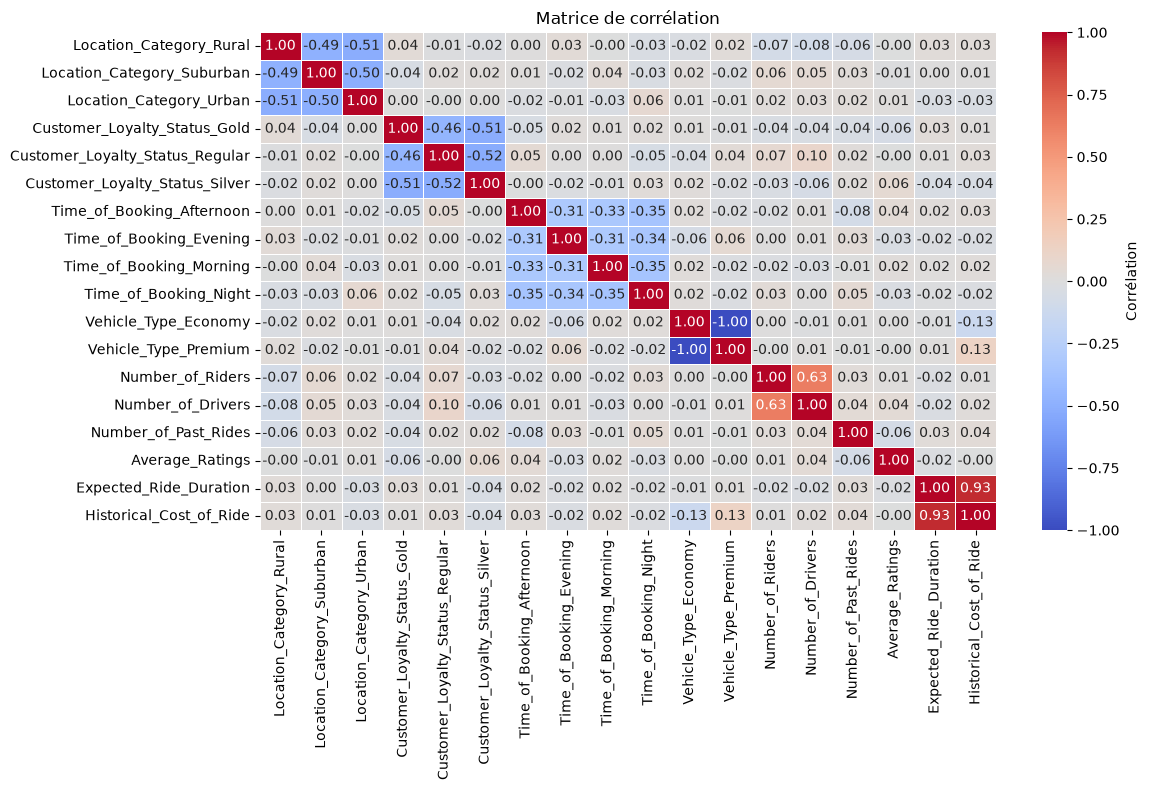

In [62]:
corr = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar= True,
    cbar_kws={'label': 'Corrélation'}
)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()